# 1.2 - Exploration + baselines (LR, RF) - M3

Goal: explore drivers of `grave` on **train only**, then fit two baselines for the **22 Oct** meeting.

1. Severe rate by key variables + association measures → hypotheses.
2. Logistic Regression and Random Forest in an sklearn `Pipeline` (stratified 5-fold CV on train, final check on test).
3. Findings and limits.

**Inputs:** `data/accidentes_train.csv`, `accidentes_test.csv`.
**Target:** `grave` = `heridos_graves>0 OR victimas_mortales>0`

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

DATA_DIR = Path("data")
if not (DATA_DIR / "accidentes_train.csv").exists():
    DATA_DIR = Path("1_2_severity/data")

train = pd.read_csv(DATA_DIR / "accidentes_train.csv")
test = pd.read_csv(DATA_DIR / "accidentes_test.csv")
TARGET = "grave"
RANDOM_STATE = 42

EXPECTED = [
    "tipo_colision", "estado_firme", "tipo_via", "ubicacion", "tipo_accidente",
    "circulacion", "franja_horaria", "carretera_grupo", "distrito",
    "vehiculos_implicados", "con_moto", "con_pesado", "hora_decimal", TARGET,
]
missing = [c for c in EXPECTED if c not in train.columns or c not in test.columns]
if missing:
    raise KeyError(f"missing columns {missing} in {(DATA_DIR / 'accidentes_train.csv').resolve()}")

def rate(s):
    return f"{100 * s.mean():.2f}% ({int(s.sum())}/{len(s)})"

print("loaded:", (DATA_DIR / "accidentes_train.csv").resolve())
print("train:", train.shape, "grave", rate(train[TARGET]))
print("test: ", test.shape, "grave", rate(test[TARGET]))
BASE_RATE = train[TARGET].mean()
train.head(3)

loaded: /Users/lukas/dev/UC3M/Project-UC3M/1_2_severity/data/accidentes_train.csv
train: (1569, 14) grave 2.29% (36/1569)
test:  (393, 14) grave 2.29% (9/393)


,tipo_colision,estado_firme,tipo_via,ubicacion,tipo_accidente,circulacion,franja_horaria,carretera_grupo,distrito,vehiculos_implicados,con_moto,con_pesado,hora_decimal,grave
0,COLISIÓN POR ALCANCE,Seco y limpio,TRONCO,SUPERFICIE,Colision entre vehiculos,DENSA,tarde,M30,USERA,3.0,0,0,16.616667,0
1,Otro,Seco y limpio,VIA DE SERVICIO,SUPERFICIE,Salida de via,FLUIDA,noche,M30,HORTALEZA,1.0,1,0,3.600000,0
2,COLISIÓN POR ALCANCE,Seco y limpio,VIA DE SERVICIO,SUPERFICIE,Colision entre vehiculos,CONGESTIONADA,tarde,M30,CIUDAD LINEAL,2.0,0,0,14.850000,0


## 1. Exploration (train only)

Severe rate per level, with counts and a Wilson 95% CI. With only **36 train positives**, most per-level rates rest on a handful of cases — read the CIs, not just the point estimates.

In [3]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return max(0, c - h), min(1, c + h)

def severe_by(df, col):
    g = df.groupby(df[col].fillna("(missing)").astype(str))[TARGET].agg(n="size", grave="sum")
    g["rate_%"] = 100 * g["grave"] / g["n"]
    ci = [wilson(k, n) for k, n in zip(g["grave"], g["n"])]
    g["ci95_%"] = [f"{100*a:.1f}–{100*b:.1f}" for a, b in ci]
    g["lift"] = (g["rate_%"] / (100 * BASE_RATE)).round(2)
    return g.sort_values("rate_%", ascending=False).round({"rate_%": 2})

EXPLORE = ["franja_horaria", "con_moto", "con_pesado", "tipo_colision", "estado_firme",
           "tipo_via", "ubicacion", "tipo_accidente", "circulacion", "carretera_grupo",
           "vehiculos_implicados"]
print(f"base rate (train): {100*BASE_RATE:.2f}%")
for col in EXPLORE:
    print(f"\n=== {col} ===")
    print(severe_by(train, col).to_string())

base rate (train): 2.29%

=== franja_horaria ===
                  n  grave  rate_%    ci95_%  lift
franja_horaria                                    
noche           162     12    7.41  4.3–12.5  3.23
tarde           621     12    1.93   1.1–3.3  0.84
tarde-noche     355      6    1.69   0.8–3.6  0.74
manana          431      6    1.39   0.6–3.0  0.61

=== con_moto ===
             n  grave  rate_%    ci95_%  lift
con_moto                                     
1          307     24    7.82  5.3–11.4  3.41
0         1262     12    0.95   0.5–1.7  0.41

=== con_pesado ===
               n  grave  rate_%   ci95_%  lift
con_pesado                                    
1            128      3    2.34  0.8–6.7  1.02
0           1441     33    2.29  1.6–3.2  1.00

=== tipo_colision ===
                        n  grave  rate_%    ci95_%  lift
tipo_colision                                           
COLISIÓN FRONTAL       18      2   11.11  3.1–32.8  4.84
COLISIÓN LATERAL      245     12    4.90 

In [4]:
# District (optional feature, 25 levels): only show levels with n >= 30
d = severe_by(train, "distrito")
print("districts with >=1 grave:", int((d["grave"] > 0).sum()), "of", len(d))
d[d["n"] >= 30]

districts with >=1 grave: 14 of 25


,n,grave,rate_%,ci95_%,lift
distrito,,,,,
CARABANCHEL,76,5,6.58,2.8–14.5,2.87
SAN BLAS,75,4,5.33,2.1–12.9,2.32
VALLECAS,82,4,4.88,1.9–11.9,2.13
RETIRO,70,3,4.29,1.5–11.9,1.87
MORATALAZ,75,3,4.00,1.4–11.1,1.74
USERA,79,3,3.80,1.3–10.6,1.66
HORTALEZA,89,3,3.37,1.2–9.4,1.47
VILLAVERDE,67,2,2.99,0.8–10.2,1.30
FUENCARRAL,82,2,2.44,0.7–8.5,1.06


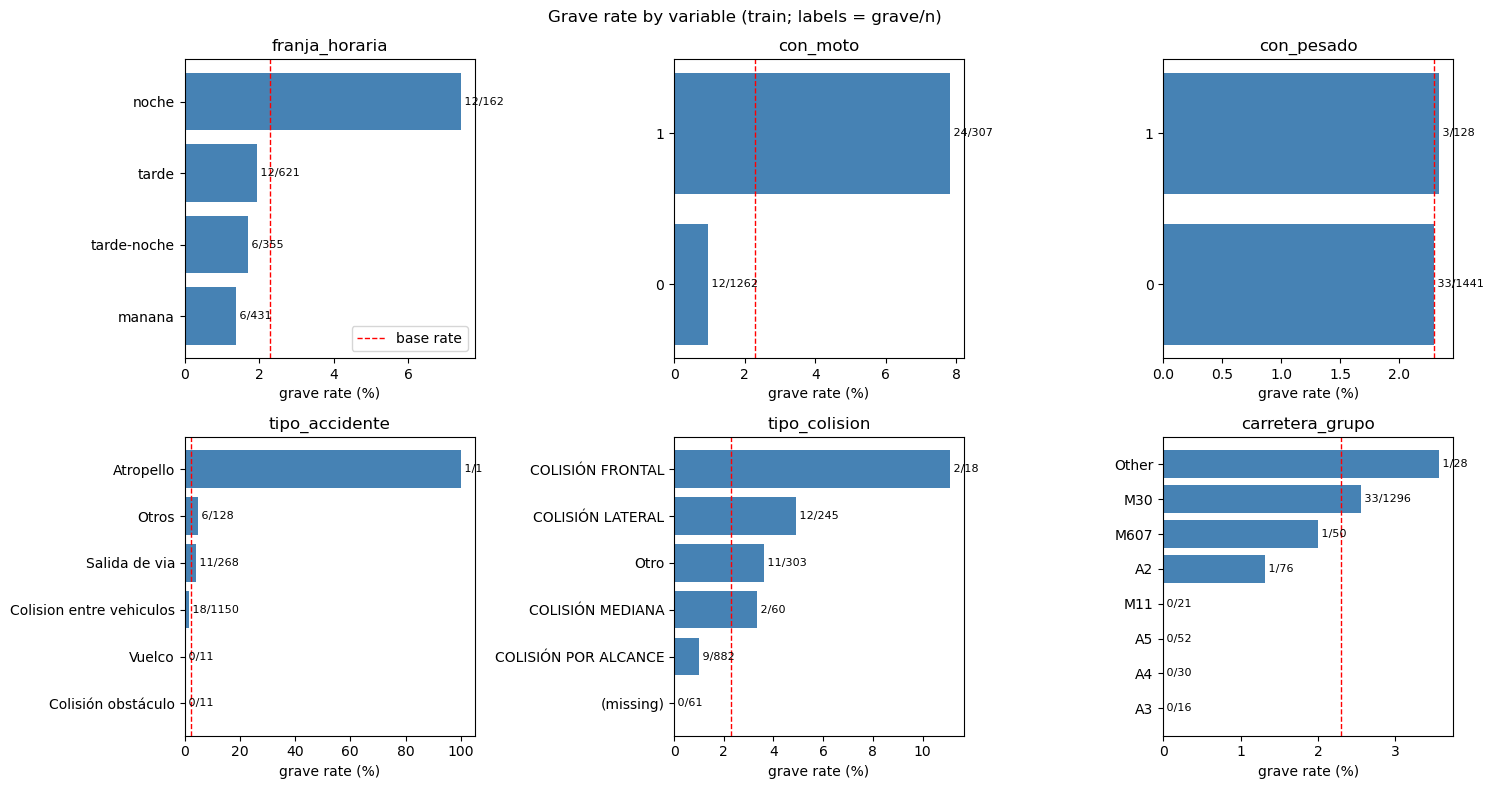

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["franja_horaria", "con_moto", "con_pesado",
                                  "tipo_accidente", "tipo_colision", "carretera_grupo"]):
    t = severe_by(train, col).sort_values("rate_%")
    ax.barh(t.index, t["rate_%"], color="steelblue")
    for i, (r, k, n) in enumerate(zip(t["rate_%"], t["grave"], t["n"])):
        ax.text(r, i, f" {k}/{n}", va="center", fontsize=8)
    ax.axvline(100 * BASE_RATE, color="red", ls="--", lw=1, label="base rate")
    ax.set_title(col)
    ax.set_xlabel("grave rate (%)")
axes[0, 0].legend(loc="lower right")
fig.suptitle("Grave rate by variable (train; labels = grave/n)")
fig.tight_layout()
plt.show()

### Association measures

- Categoricals: Cramér's V (bias-corrected) with chi² p-value; many cells have expected counts < 5, so p-values are indicative only. Fisher's exact test for the binary flags.
- Numerics: point-biserial r and Spearman ρ vs `grave`.

In [6]:
def cramers_v(x, y):
    tab = pd.crosstab(x.fillna("(missing)").astype(str), y)
    chi2, p, dof, exp = stats.chi2_contingency(tab, correction=False)
    n = tab.values.sum()
    r, k = tab.shape
    phi2 = chi2 / n
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    v = np.sqrt(phi2c / max(1e-12, min(kc - 1, rc - 1)))
    return v, np.sqrt(phi2 / min(k - 1, r - 1)), p, (exp < 5).mean()

CAT_ASSOC = ["franja_horaria", "con_moto", "con_pesado", "tipo_colision", "estado_firme",
             "tipo_via", "ubicacion", "tipo_accidente", "circulacion", "carretera_grupo", "distrito"]
rows = []
for c in CAT_ASSOC:
    v, v_raw, p, small = cramers_v(train[c], train[TARGET])
    rows.append({"variable": c, "levels": train[c].nunique(), "cramers_v_corr": v,
                 "cramers_v_raw": v_raw, "chi2_p": p, "share_cells_exp<5": small})
assoc_cat = pd.DataFrame(rows).sort_values("cramers_v_corr", ascending=False).round(4)
assoc_cat

,variable,levels,cramers_v_corr,cramers_v_raw,chi2_p,share_cells_exp<5
1,con_moto,2,0.1802,0.1819,0.0000,0.0000
7,tipo_accidente,6,0.1750,0.1838,0.0000,0.4167
3,tipo_colision,5,0.1106,0.1241,0.0002,0.2500
0,franja_horaria,4,0.1083,0.1168,0.0001,0.1250
10,distrito,25,0.0454,0.1318,0.2932,0.5600
8,circulacion,3,0.0451,0.0629,0.1024,0.1250
4,estado_firme,4,0.0207,0.0546,0.3227,0.4000
5,tipo_via,6,0.0097,0.0573,0.3977,0.2500
2,con_pesado,2,0.0000,0.0010,0.9690,0.2500
6,ubicacion,2,0.0000,0.0007,0.9792,0.0000


In [7]:
for flag in ["con_moto", "con_pesado"]:
    tab = pd.crosstab(train[flag], train[TARGET])
    odds, p = stats.fisher_exact(tab.values)
    print(f"{flag}: odds ratio = {odds:.2f}, Fisher p = {p:.4f}\n{tab}\n")

rows = []
for c in ["vehiculos_implicados", "hora_decimal", "con_moto", "con_pesado"]:
    s = train[[c, TARGET]].dropna()
    pb = stats.pointbiserialr(s[TARGET], s[c])
    sp = stats.spearmanr(s[c], s[TARGET])
    rows.append({"variable": c, "n": len(s), "point_biserial_r": pb.statistic, "pb_p": pb.pvalue,
                 "spearman_rho": sp.statistic, "sp_p": sp.pvalue,
                 "mean_if_grave": s.loc[s[TARGET] == 1, c].mean(),
                 "mean_if_not": s.loc[s[TARGET] == 0, c].mean()})
assoc_num = pd.DataFrame(rows).round(4)
assoc_num

con_moto: odds ratio = 8.83, Fisher p = 0.0000
grave        0   1
con_moto          
0         1250  12
1          283  24

con_pesado: odds ratio = 1.02, Fisher p = 1.0000
grave          0   1
con_pesado          
0           1408  33
1            125   3



,variable,n,point_biserial_r,pb_p,spearman_rho,sp_p,mean_if_grave,mean_if_not
0,vehiculos_implicados,1558,-0.0646,0.0108,-0.0758,0.0028,1.6571,2.0046
1,hora_decimal,1569,0.0062,0.8050,0.0120,0.6348,14.0991,13.8768
2,con_moto,1569,0.1819,0.0000,0.1819,0.0000,0.6667,0.1846
3,con_pesado,1569,0.0010,0.9690,0.0010,0.9690,0.0833,0.0815


### Hypotheses (from train; to test in M4)

Small-n caveat: 36 train positives; most levels have < 15 severe cases and wide CIs.

1. **Motorcycles drive severity.** `con_moto=1`: 7.0% vs 1.1% (21/301 vs 15/1349; OR ≈ 6.7, Fisher p < 0.001; strongest Cramér's V 0.15). More than half of severe cases involve a moto.
2. **Night is riskier.** `noche` (22–5h): 6.9% (12/174), ~3× base rate; other bands 1.1–1.9%. Raw `hora_decimal` has no linear association (r ≈ 0) — the effect is non-linear, so a band/cyclic encoding matters.
3. **Rear-end collisions are the least severe.** `Colision por alcance` 1.1% (10/921) vs lateral 4.5% (11/243) and frontal 7.7% (2/26); `Colision entre vehiculos` 1.6% vs `Salida de via` 3.1%.
4. **Dense traffic protects (lower speed).** `Densa` 0.4% (2/482) vs ~3% for fluid or congested — counter-intuitive for `Congestionada`; check for coding overlap.
5. **`vehiculos_implicados = 0` is a data signal, not physics.** 6/14 severe (all `tipo_accidente=Otros`): likely pedestrian/unregistered-vehicle cases. Weather (`Mojado` 0/169), road group and district show no reliable signal (V ≈ 0).

## 2. Baselines

- Features: 8 categoricals + `vehiculos_implicados`, `con_moto`, `con_pesado`, `hora_decimal`. `distrito` (25 levels) is left out of the main run and tried as a CV-only sensitivity check.
- Never used: `heridos_leves`, `heridos_graves`, `victimas_mortales`, anything derived from `grave`, IDs, `descripcion` (none are in the processed files — asserted below).
- Pipeline: impute (most-frequent / median) → OneHot(`handle_unknown='ignore'`); numerics scaled for LR.
- Evaluation: stratified 5-fold CV PR-AUC on train; threshold = max severe-class F1 on **out-of-fold** predictions; then a single fit on full train scored on test.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

CAT = ["tipo_colision", "estado_firme", "tipo_via", "ubicacion", "tipo_accidente",
       "circulacion", "franja_horaria", "carretera_grupo"]
NUM = ["vehiculos_implicados", "con_moto", "con_pesado", "hora_decimal"]
FORBIDDEN = {"heridos_leves", "heridos_graves", "victimas_mortales", "numero_incidencia",
             "localizacion", "eje", "unidad_samur_id", "descripcion", TARGET}
assert not FORBIDDEN & set(CAT + NUM), "leakage column in feature list"
leakage = (FORBIDDEN - {TARGET}) & (set(train.columns) | set(test.columns))
assert not leakage, f"leakage columns present in the files: {sorted(leakage)}"

X_train, y_train = train[CAT + NUM], train[TARGET].values
X_test, y_test = test[CAT + NUM], test[TARGET].values

def make_pre(cat, num, scale):
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("cat", cat_pipe, cat), ("num", Pipeline(num_steps), num)])

def make_lr(cat=CAT, num=NUM):
    return Pipeline([("pre", make_pre(cat, num, scale=True)),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))])

def make_rf(cat=CAT, num=NUM):
    return Pipeline([("pre", make_pre(cat, num, scale=False)),
                     ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                                    class_weight="balanced_subsample",
                                                    n_jobs=-1, random_state=RANDOM_STATE))])

MODELS = {"LogReg (balanced)": make_lr, "RandomForest (bal. subsample)": make_rf}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("positives per CV validation fold:", [int(y_train[v].sum()) for _, v in cv.split(X_train, y_train)])

positives per CV validation fold: [7, 7, 7, 8, 7]


In [9]:
def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    i = int(np.nanargmax(f1))
    return thr[i], f1[i]

results, oof, test_proba, fitted = {}, {}, {}, {}
for name, make in MODELS.items():
    cvres = cross_validate(make(), X_train, y_train, cv=cv,
                           scoring={"ap": "average_precision", "roc": "roc_auc"})
    p_oof = cross_val_predict(make(), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    thr, f1_oof = best_f1_threshold(y_train, p_oof)
    model = make().fit(X_train, y_train)
    p_test = model.predict_proba(X_test)[:, 1]
    yhat = (p_test >= thr).astype(int)
    oof[name], test_proba[name], fitted[name] = p_oof, p_test, model
    results[name] = {
        "CV PR-AUC mean": cvres["test_ap"].mean(), "CV PR-AUC sd": cvres["test_ap"].std(),
        "CV ROC-AUC mean": cvres["test_roc"].mean(),
        "OOF PR-AUC": average_precision_score(y_train, p_oof),
        "threshold (OOF max-F1)": thr, "OOF F1 @thr": f1_oof,
        "test PR-AUC": average_precision_score(y_test, p_test),
        "test ROC-AUC": roc_auc_score(y_test, p_test),
        "test precision @thr": precision_score(y_test, yhat, zero_division=0),
        "test recall @thr": recall_score(y_test, yhat),
        "test F1 @thr": f1_score(y_test, yhat, zero_division=0),
        "test flagged": int(yhat.sum()),
    }
    print(f"{name}: CV fold PR-AUC = {np.round(cvres['test_ap'], 3)}")

results["Base rate (no skill)"] = {"CV PR-AUC mean": BASE_RATE, "OOF PR-AUC": BASE_RATE,
                                   "test PR-AUC": y_test.mean(), "test ROC-AUC": 0.5}
comparison = pd.DataFrame(results).T.round(3)
comparison

LogReg (balanced): CV fold PR-AUC = [0.119 0.111 0.092 0.229 0.112]
RandomForest (bal. subsample): CV fold PR-AUC = [0.126 0.246 0.15  0.199 0.108]


,CV PR-AUC mean,CV PR-AUC sd,CV ROC-AUC mean,OOF PR-AUC,threshold (OOF max-F1),OOF F1 @thr,test PR-AUC,test ROC-AUC,test precision @thr,test recall @thr,test F1 @thr,test flagged
LogReg (balanced),0.133,0.049,0.789,0.095,0.846,0.174,0.116,0.867,0.118,0.222,0.154,17.0
RandomForest (bal. subsample),0.166,0.050,0.796,0.126,0.399,0.232,0.109,0.830,0.135,0.556,0.217,37.0
Base rate (no skill),0.023,NaN,NaN,0.023,NaN,NaN,0.023,0.500,NaN,NaN,NaN,NaN


LogReg (balanced) — test confusion matrix @thr=0.846  [rows: true 0/1, cols: pred 0/1]
        pred 0  pred 1
true 0     369      15
true 1       7       2 

RandomForest (bal. subsample) — test confusion matrix @thr=0.399  [rows: true 0/1, cols: pred 0/1]
        pred 0  pred 1
true 0     352      32
true 1       4       5 



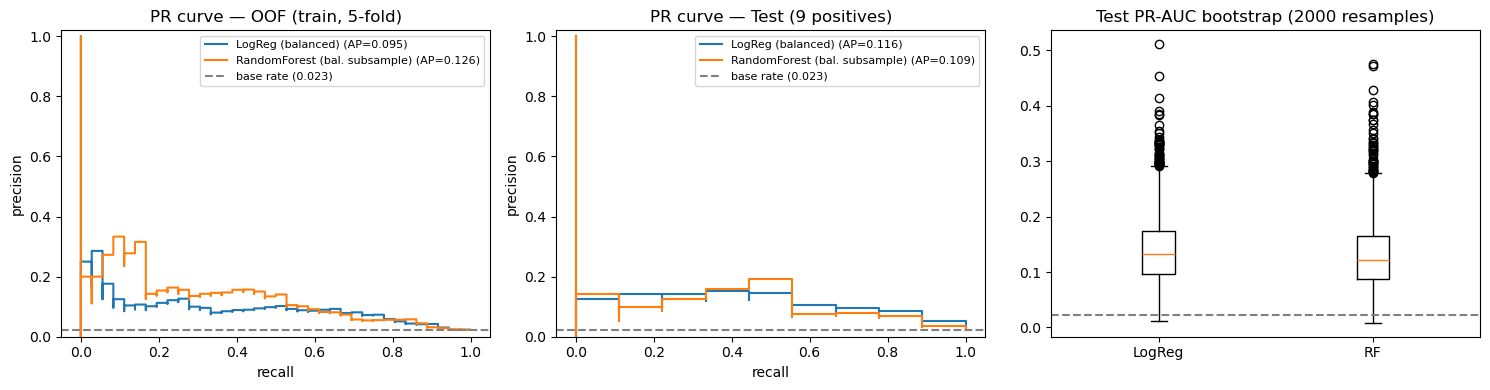

LogReg (balanced): test PR-AUC 95% bootstrap CI = [0.046, 0.278]
RandomForest (bal. subsample): test PR-AUC 95% bootstrap CI = [0.038, 0.272]


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name in MODELS:
    thr = results[name]["threshold (OOF max-F1)"]
    cm = confusion_matrix(y_test, (test_proba[name] >= thr).astype(int))
    print(f"{name} — test confusion matrix @thr={thr:.3f}  [rows: true 0/1, cols: pred 0/1]")
    print(pd.DataFrame(cm, index=["true 0", "true 1"], columns=["pred 0", "pred 1"]), "\n")

for ax, (title, y, P) in zip(axes[:2], [("OOF (train, 5-fold)", y_train, oof),
                                         ("Test (9 positives)", y_test, test_proba)]):
    for name, p in P.items():
        prec, rec, _ = precision_recall_curve(y, p)
        ax.step(rec, prec, where="post", label=f"{name} (AP={average_precision_score(y, p):.3f})")
    ax.axhline(y.mean(), color="grey", ls="--", label=f"base rate ({y.mean():.3f})")
    ax.set(title=f"PR curve — {title}", xlabel="recall", ylabel="precision", ylim=(0, 1.02))
    ax.legend(fontsize=8)

# bootstrap 95% CI for test PR-AUC (shows how noisy 9 positives are)
rng = np.random.default_rng(RANDOM_STATE)
boot = {n: [] for n in MODELS}
for _ in range(2000):
    idx = rng.integers(0, len(y_test), len(y_test))
    if y_test[idx].sum() == 0:
        continue
    for n in MODELS:
        boot[n].append(average_precision_score(y_test[idx], test_proba[n][idx]))
axes[2].boxplot([boot[n] for n in MODELS])
axes[2].set_xticklabels(["LogReg", "RF"])
axes[2].axhline(y_test.mean(), color="grey", ls="--")
axes[2].set_title("Test PR-AUC bootstrap (2000 resamples)")
fig.tight_layout()
plt.show()
for n in MODELS:
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    print(f"{n}: test PR-AUC 95% bootstrap CI = [{lo:.3f}, {hi:.3f}]")

In [11]:
# Sensitivity (CV only): does adding distrito help?
for name, make in MODELS.items():
    s = cross_validate(make(CAT + ["distrito"], NUM), train[CAT + ["distrito"] + NUM], y_train,
                       cv=cv, scoring="average_precision")["test_score"]
    print(f"{name} + distrito: CV PR-AUC = {s.mean():.3f} ± {s.std():.3f}  "
          f"(without: {results[name]['CV PR-AUC mean']:.3f} ± {results[name]['CV PR-AUC sd']:.3f})")

LogReg (balanced) + distrito: CV PR-AUC = 0.150 ± 0.099  (without: 0.133 ± 0.049)
RandomForest (bal. subsample) + distrito: CV PR-AUC = 0.174 ± 0.038  (without: 0.166 ± 0.050)


### Drivers

LR: standardized coefficients (one-hot vs. most-frequent levels is not a reference coding — read as relative log-odds). RF: impurity importance, also summed back to the original variable (impurity favours high-cardinality/continuous inputs like `hora_decimal`).

Top + (raise grave odds):
                                      coef  odds_ratio
cat__estado_firme_Otros              2.882      17.847
cat__tipo_accidente_Atropello        2.267       9.650
cat__carretera_grupo_M607            2.021       7.545
cat__franja_horaria_noche            1.387       4.003
cat__tipo_via_VIA DE SERVICIO        1.344       3.833
cat__tipo_colision_COLISIÓN FRONTAL  1.293       3.642
num__con_moto                        1.117       3.056
cat__carretera_grupo_A2              1.086       2.962

Top − (lower grave odds):
                                          coef  odds_ratio
cat__estado_firme_Mojado                -2.830       0.059
cat__carretera_grupo_A5                 -1.598       0.202
cat__tipo_accidente_Colisión obstáculo  -1.260       0.284
cat__tipo_colision_COLISIÓN POR ALCANCE -1.210       0.298
cat__tipo_via_TUNEL                     -1.150       0.317


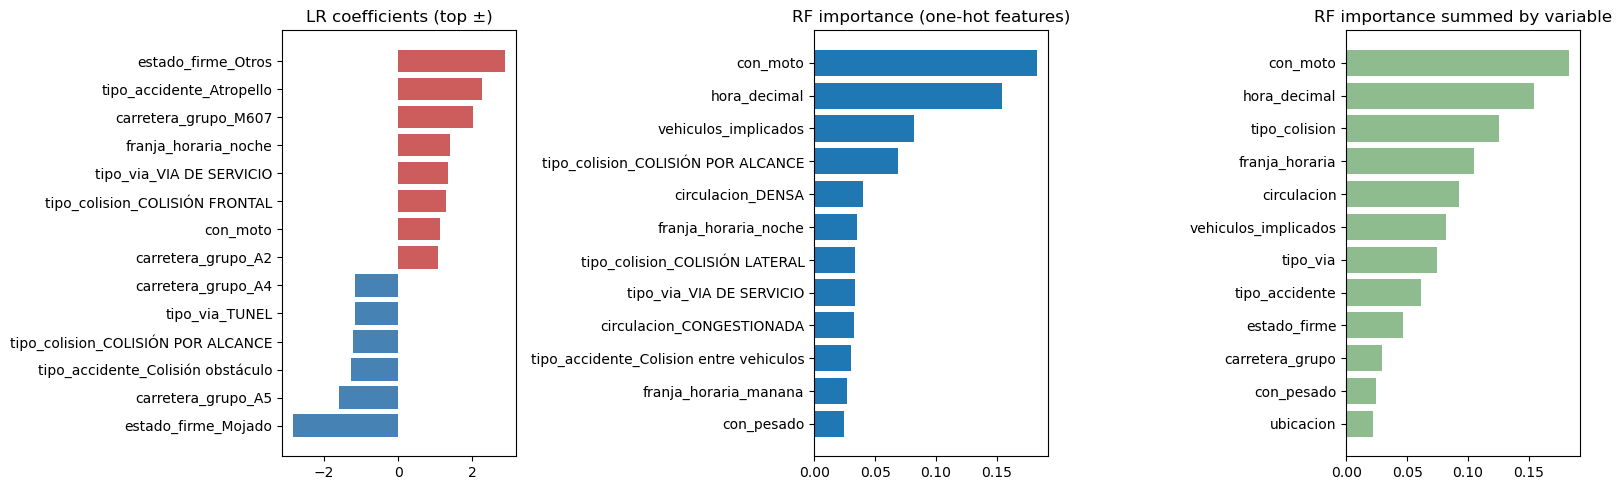

,rf_importance
con_moto,0.183
hora_decimal,0.154
tipo_colision,0.125
franja_horaria,0.105
circulacion,0.092
vehiculos_implicados,0.082
tipo_via,0.074
tipo_accidente,0.061
estado_firme,0.047
carretera_grupo,0.030


In [12]:
lr = fitted["LogReg (balanced)"]
names = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=names)
coef_tbl = pd.DataFrame({"coef": coef, "odds_ratio": np.exp(coef)}).sort_values("coef")
print("Top + (raise grave odds):")
print(coef_tbl.tail(8)[::-1].round(3).to_string())
print("\nTop − (lower grave odds):")
print(coef_tbl.head(5).round(3).to_string())

rf = fitted["RandomForest (bal. subsample)"]
imp = pd.Series(rf.named_steps["clf"].feature_importances_,
                index=rf.named_steps["pre"].get_feature_names_out()).sort_values(ascending=False)
def orig(f):
    f = f.split("__", 1)[1]
    for c in CAT + NUM:
        if f == c or f.startswith(c + "_"):
            return c
    return f
imp_var = imp.groupby(imp.index.map(orig)).sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
top = pd.concat([coef_tbl.head(6), coef_tbl.tail(8)])["coef"]
axes[0].barh([n.split("__", 1)[1] for n in top.index], top.values,
             color=["indianred" if v > 0 else "steelblue" for v in top.values])
axes[0].set_title("LR coefficients (top ±)")
axes[1].barh([n.split("__", 1)[1] for n in imp.head(12).index[::-1]], imp.head(12).values[::-1])
axes[1].set_title("RF importance (one-hot features)")
axes[2].barh(imp_var.index[::-1], imp_var.values[::-1], color="darkseagreen")
axes[2].set_title("RF importance summed by variable")
fig.tight_layout()
plt.show()
imp_var.round(3).to_frame("rf_importance")

## 3. Findings and limits

- **Both baselines beat the base rate (0.022)**: CV PR-AUC LR 0.104 ± 0.037, RF 0.205 ± 0.108; test PR-AUC LR 0.083, RF 0.116; test ROC-AUC ~0.84–0.86. Useful ranking, weak precision.
- **RF > LR on PR-AUC** in CV and test, consistent with non-linear effects (`hora_decimal`, `vehiculos_implicados=0`). LR with default C over-weights rare levels (`estado_firme=Otros`, n=26 with 1 positive; `Atropello`, n=2).
- **Drivers agree with exploration**: `con_moto`, collision type, night/`hora_decimal`, traffic density, number of vehicles.
- **Thresholds do not transfer**: OOF max-F1 thresholds give test F1 = 0.14 for both — LR flags 47 (recall 4/9, precision 0.09), RF flags 5 (recall 1/9). Choosing a threshold on 36 positives is unstable.
- **Noise**: test has 9 positives; bootstrap 95% CI for test PR-AUC is ~0.03–0.21 (LR) and ~0.04–0.36 (RF); CV fold SDs are large. Differences between models are not statistically solid.
- `distrito` slightly hurts CV PR-AUC for both models → keep it out.

**Next (M4):** LightGBM, regularisation tuning (LR `C`, RF depth/leaf), repeated stratified CV, threshold strategy (recall-targeted, e.g. ≥ 0.7, cost-based), probability calibration; check what `vehiculos_implicados=0` encodes.